## Transfer Learning Project

Aaron Yalong, Maximilian Garcia

In [1]:
# import libraries, dependencies, and packages

# torch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# torchvision
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, random_split

# visualization
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

KeyboardInterrupt: 

In [ ]:
# random seed for this project
torch.manual_seed(7)
np.random.seed(7)

In [ ]:
# device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# gpu available
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


## Step 1 & 2 : Data Loading and Preprocessing

In [ ]:
# baseline CNN and improved CNN

# training set transformation
cnn_train_transform = transforms.Compose([
    transforms.ToTensor(),                                 # convert to to tensors
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # normalize mean and standard deviation set to 0.5 for range [-1,1]
])


# test/validation set transformation
cnn_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.ToTensor(),                                 # convert to to tensors
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # normalize mean and standard deviation set to 0.5 for range [-1,1]
])

In [ ]:
# resnet18

# training set transformation
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),       # resize
    transforms.ToTensor(),               # pytorch conversion
    transforms.Normalize(                # normalize using imagenet's mean and std values
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# test/validation set transformation
resnet_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),       # resize
    transforms.ToTensor(),               # pytorch conversion
    transforms.Normalize(                # normalize using imagenet's mean and std values
        # imagenet's mean and std values
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# cnn test and train dataset downloads
train_dataset_cnn = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=cnn_train_transform)
test_dataset_cnn = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=cnn_test_transform)

100%|██████████| 170M/170M [00:12<00:00, 13.4MB/s]


In [ ]:
# resnet dataset downloads
train_dataset_resnet = torchvision.datasets.CIFAR10(root="./data", train=True, download=False, transform=resnet_train_transform)
test_dataset_resnet = torchvision.datasets.CIFAR10(root="./data", train=False, download=False, transform=resnet_test_transform)

In [ ]:
# split data into (90% train) and (10% validation)
train_size = 45000
val_size = 5000

# cnn
train_subset_cnn, val_subset_cnn = random_split(
    train_dataset_cnn,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(7)
)

# resnet
train_subset_resnet, val_subset_resnet = random_split(
    train_dataset_resnet,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(7)
)

In [ ]:
# cnn
cnn_batch_size = 8
train_loader_cnn = DataLoader(train_subset_cnn, batch_size=cnn_batch_size, shuffle=True, num_workers=0)
val_loader_cnn = DataLoader(val_subset_cnn, batch_size=cnn_batch_size, shuffle=False, num_workers=0)
test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=cnn_batch_size, shuffle=False, num_workers=0)

# resnet
resnet_batch_size = 8
train_loader_resnet = DataLoader(train_subset_resnet, batch_size=resnet_batch_size, shuffle=True, num_workers=0)
val_loader_resnet = DataLoader(val_subset_resnet, batch_size=resnet_batch_size, shuffle=False, num_workers=0)
test_loader_resnet = DataLoader(test_dataset_resnet, batch_size=resnet_batch_size, shuffle=False, num_workers=0)


In [ ]:
# cifar10

# classes
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']

print("CNN & Improved CNN pipeline")
print(f"Training data: {len(train_subset_cnn)}")
print(f"Validation data: {len(val_subset_cnn)}")
print(f"Test data: {len(test_dataset_cnn)}")
print(f"Batch: {cnn_batch_size}")
print(f"")
print("ResNet pipeline")
print(f"Training data: {len(train_subset_resnet)}")
print(f"Validation data: {len(val_subset_resnet)}")
print(f"Test data: {len(test_dataset_resnet)}")
print(f"Batch: {resnet_batch_size}")


CNN & Improved CNN pipeline
Training data: 45000
Validation data: 5000
Test data: 10000
Batch: 8

ResNet pipeline
Training data: 45000
Validation data: 5000
Test data: 10000
Batch: 8


## Step 3: Model Architectures

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)       # first conv layer - 3 channels, 6 feature maps, and 5x5 kernel size
        self.pool = nn.MaxPool2d(2, 2)        # reduce dimensions
        self.conv2 = nn.Conv2d(6, 16, 5)      # second conv layer - 3 channels, 16 feature maps, and 5x5 kernel size

        self.fc1 = nn.Linear(16 * 5 * 5, 120) # fully connected layer 1
        self.fc2 = nn.Linear(120, 84)         # fully connected layer 2
        self.fc3 = nn.Linear(84, 10)          # output layer -> 10 classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # conv1 -> ReLU -> pooling
        x = self.pool(F.relu(self.conv2(x))) # conv2 -> ReLU -> pooling

        x = torch.flatten(x, 1)              # flatten into 1D

        x = F.relu(self.fc1(x))              # connected layers with ReLU
        x = F.relu(self.fc2(x))

        x = self.fc3(x)                      # output layer
        return x

In [ ]:
class custom_CNN(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super(custom_CNN, self).__init__()

        # convolutional layers
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)     # increased filters -> more image features
        self.bn1 = nn.BatchNorm2d(32)                   # batchnorm -> stabilize training and improve convergence

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)    # increased filters -> more image features
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)   # 3rd conv layer
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)                  # pooling to reduce dimensions

        # fully connected layers
        self.fc1 = nn.Linear(128 * 4 * 4, 256)          # larger layer -> stronger feature learnign
        self.fc2 = nn.Linear(256, 10)

        self.dropout = nn.Dropout(dropout_rate)         # reduce overfitting

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))  # conv -> BatchNorm -> ReLU -> Pool
        x = self.pool(F.relu(self.bn2(self.conv2(x))))  # conv block 2
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # extra conv block 3

        x = torch.flatten(x, 1)                         # flatten
        x = self.dropout(F.relu(self.fc1(x)))           # regularization ReLu + Dropout
        x = self.fc2(x)                                 # output layer

        return x

In [ ]:
def pretrained_ResNet(strategy='frozen'):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)    # load pretrained ResNet18 (trained on ImageNet)

    num_features = model.fc.in_features                                 # modify final layer for CIFAR-10 (10 classes instead of 1000)
    model.fc = nn.Linear(num_features, 10)                              # replace classifier layer

    # freeze layers
    if strategy == 'frozen':
        for param in model.parameters():          # feature extraction
            param.requires_grad = False
        for param in model.fc.parameters():       # unfreeze final layer -> only classifier learns CIFAR-10
            param.requires_grad = True

    elif strategy == 'full':                      # train entire network -> fine-tuning all layers
        pass

    return model

## Step 4: Training and Evaluation Functions

---



In [ ]:
# training data
def epoch(model, train_loader, criterion, optimizer, device):

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100.0 * correct / total
    return epoch_loss, epoch_acc


In [ ]:
# validation data
def validate(model, val_loader, criterion, device):

    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(val_loader)
    val_acc = 100.0 * correct / total
    return val_loss, val_acc


In [ ]:
def train_model(model, model_name, num_epochs=50, learning_rate=0.001,
                use_scheduler=True, patience=10):

    print(f"\nTraining {model_name}...")
    print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    model = model.to(device)                                                    # move model to cpu/gpu
    criterion = nn.CrossEntropyLoss()                                           # loss function for multi-class classification

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),                  # only optimize trainable params
        lr=learning_rate,
        weight_decay=1e-4                                                       # L2 regularization -> reduce overfitting
    )

    scheduler = None
    if use_scheduler:
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.1)  # reduce LR every 15 epochs

    # store training history for plots
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    best_val_acc = 0.0                                                            # track best validation accuracy
    best_epoch = 0                                                                # track epoch with best performance
    epochs_without_improvement = 0                                                # early stopping counter
    save_path = f"best_{model_name.replace(' ', '_')}.pth"                        # save best model weights
    start_time = time.time()                                                      # track total training time

    # save initial weights in case validation accuracy never improves
    torch.save(model.state_dict(), save_path)

    for e in range(num_epochs):
        train_loss, train_acc = epoch(model, train_loader, criterion, optimizer, device)    # training step
        val_loss, val_acc = validate(model, val_loader, criterion, device)                  # validation step

        # Record history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if (e + 1) % 5 == 0:
            current_lr = optimizer.param_groups[0]['lr']  #get current learning rate
            print(
                f"Epoch [{e+1}/{num_epochs}] "
                f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}% | "
                f"LR: {current_lr:.6f}"
            )

        if val_acc > best_val_acc:
            best_val_acc = val_acc                        # update best validation accuracy
            best_epoch = e + 1                            # save best epoch
            epochs_without_improvement = 0                # reset patience counter
            torch.save(model.state_dict(), save_path)     # save best model
        else:
            epochs_without_improvement += 1               # no improvement -> increase counter

        if scheduler is not None:
            scheduler.step()                              # update learning rate

        if epochs_without_improvement >= patience:
            print(f"Early stoppage at epoch {e+1}")       # stop if no improvement for set patience
            break

    total_time = time.time() - start_time                                       # total training time
    model.load_state_dict(torch.load(save_path, map_location=device))           # load best saved weights

    print(f"Training time: {total_time:.2f}")
    print(f"Best validation accuracy: {best_val_acc:.2f}% at epoch {best_epoch}")

    return {
        'model': model,
        'history': history,
        'best_val_acc': best_val_acc,
        'best_epoch': best_epoch,
        'total_time': total_time
    }

## Step 5: Train All Models and Compare Results


In [21]:
all_results = []      # storing results

In [ ]:
# CNN
train_loader = train_loader_cnn
val_loader = val_loader_cnn
test_loader = test_loader_cnn

baseline_model = CNN()
baseline_results = train_model(
    model=baseline_model,
    model_name="CNN",
    num_epochs=30,
    learning_rate=0.001,
    use_scheduler=True,
    patience=10
)



Training CNN...
Total parameters: 62,006
Trainable parameters: 62,006
Epoch [5/30] Train Loss: 0.9993, Train Acc: 64.76% | Val Loss: 1.1015, Val Acc: 61.54% | LR: 0.001000
Epoch [10/30] Train Loss: 0.8330, Train Acc: 70.42% | Val Loss: 1.1393, Val Acc: 62.36% | LR: 0.001000
Epoch [15/30] Train Loss: 0.7296, Train Acc: 74.09% | Val Loss: 1.2267, Val Acc: 61.62% | LR: 0.001000
Epoch [20/30] Train Loss: 0.4321, Train Acc: 84.84% | Val Loss: 1.2662, Val Acc: 65.08% | LR: 0.000100
Epoch [25/30] Train Loss: 0.3589, Train Acc: 87.65% | Val Loss: 1.4132, Val Acc: 64.92% | LR: 0.000100
Early stoppage at epoch 28
Training time: 217.08
Best validation accuracy: 65.28% at epoch 18


In [ ]:
# custom CNN
train_loader = train_loader_cnn
val_loader = val_loader_cnn
test_loader = test_loader_cnn

improved_model = custom_CNN(dropout_rate=0.5)
improved_results = train_model(
    model=improved_model,
    model_name="custom CNN",
    num_epochs=30,
    learning_rate=0.001,
    use_scheduler=True,
    patience=10
)


Training custom CNN...
Total parameters: 620,810
Trainable parameters: 620,810
Epoch [5/30] Train Loss: 0.8049, Train Acc: 72.61% | Val Loss: 0.7151, Val Acc: 74.84% | LR: 0.001000
Epoch [10/30] Train Loss: 0.5489, Train Acc: 81.20% | Val Loss: 0.6895, Val Acc: 76.96% | LR: 0.001000
Epoch [15/30] Train Loss: 0.4351, Train Acc: 85.08% | Val Loss: 0.6955, Val Acc: 78.16% | LR: 0.001000
Epoch [20/30] Train Loss: 0.1478, Train Acc: 94.86% | Val Loss: 0.6926, Val Acc: 81.54% | LR: 0.000100
Epoch [25/30] Train Loss: 0.0955, Train Acc: 96.88% | Val Loss: 0.7275, Val Acc: 81.30% | LR: 0.000100
Epoch [30/30] Train Loss: 0.0694, Train Acc: 97.83% | Val Loss: 0.7956, Val Acc: 80.82% | LR: 0.000100
Training time: 273.11
Best validation accuracy: 81.66% at epoch 21


In [ ]:
train_loader = train_loader_resnet
val_loader = val_loader_resnet
test_loader = test_loader_resnet

resnet_full = pretrained_ResNet(strategy='full')
resnet_full_results = train_model(
    model=resnet_full,
    model_name="ResNet18 Full",
    num_epochs=30,
    learning_rate=0.0001,
    use_scheduler=True,
    patience=8
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]



Training ResNet18 Full...
Total parameters: 11,181,642
Trainable parameters: 11,181,642
Epoch [5/30] Train Loss: 0.1145, Train Acc: 96.29% | Val Loss: 0.2369, Val Acc: 92.84% | LR: 0.000100
Epoch [10/30] Train Loss: 0.0646, Train Acc: 97.94% | Val Loss: 0.2521, Val Acc: 92.52% | LR: 0.000100
Early stoppage at epoch 12
Training time: 513.84
Best validation accuracy: 93.54% at epoch 4


In [ ]:
train_loader = train_loader_resnet
val_loader = val_loader_resnet
test_loader = test_loader_resnet

resnet_frozen = pretrained_ResNet(strategy='frozen')
resnet_frozen_results = train_model(
    model=resnet_frozen,
    model_name="ResNet18 Frozen",
    num_epochs=20,
    learning_rate=0.001,
    use_scheduler=False,
    patience=5
)



Training ResNet18 Frozen...
Total parameters: 11,181,642
Trainable parameters: 5,130
Epoch [5/20] Train Loss: 0.8077, Train Acc: 72.87% | Val Loss: 0.6683, Val Acc: 78.04% | LR: 0.001000
Epoch [10/20] Train Loss: 0.8042, Train Acc: 73.02% | Val Loss: 0.6841, Val Acc: 77.44% | LR: 0.001000
Epoch [15/20] Train Loss: 0.8044, Train Acc: 73.04% | Val Loss: 0.6186, Val Acc: 79.82% | LR: 0.001000
Epoch [20/20] Train Loss: 0.7958, Train Acc: 73.30% | Val Loss: 0.6253, Val Acc: 79.86% | LR: 0.001000
Training time: 565.96
Best validation accuracy: 80.36% at epoch 18


Step 5b: Gradual Unfreezing

In [ ]:
def unfreeze_resnet_layers(model, unfreeze_up_to):
    layer_groups = ['fc', 'layer4', 'layer3', 'layer2', 'layer1', 'conv1', 'bn1'] # layer groups ordered from output (head) → input (early features)
    unfreeze_order = {                                                 # define how much of the network to unfreeze
        'fc':     ['fc'],                                              # train classifier only
        'layer4': ['fc', 'layer4'],                                    # unfreeze highest-level features
        'layer3': ['fc', 'layer4', 'layer3'],                          # include mid-level features
        'layer2': ['fc', 'layer4', 'layer3', 'layer2'],                # deeper unfreezing
        'layer1': ['fc', 'layer4', 'layer3', 'layer2', 'layer1'],      # almost full network
        'all':    layer_groups                                         # full fine-tuning
    }

    for param in model.parameters():                                   # freeze all layers first -> prevent unwanted updates
        param.requires_grad = False

    groups_to_unfreeze = unfreeze_order.get(unfreeze_up_to, ['fc'])    # selectively unfreeze layers based on stage

    for name, module in model.named_children():
        if name in groups_to_unfreeze:
            for param in module.parameters():
                param.requires_grad = True
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)   # count trainable parameters -> track how much of the model is being updated
    total = sum(p.numel() for p in model.parameters())

    print(f"  Unfrozen up to '{unfreeze_up_to}': {trainable:,} / {total:,} trainable params")

    return model

In [ ]:
def train_gradual_unfreezing(model, model_name, unfreeze_schedule, device,train_loader, val_loader, base_lr=0.001, weight_decay=1e-4, patience=5):

    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)                                # label smoothing helps with transfer

    all_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0
    best_epoch = 0
    save_path = f"best_{model_name.replace(' ', '_')}.pth"
    torch.save(model.state_dict(), save_path)
    global_epoch = 0
    start_time = time.time()

    print(f"\nGradual Unfreezing: {model_name}")

    for phase_idx, (n_epochs, layer_group, lr) in enumerate(unfreeze_schedule):
        print(f"\n--- Phase {phase_idx+1}: unfreeze up to '{layer_group}', lr={lr}, epochs={n_epochs} ---")
        model = unfreeze_resnet_layers(model, layer_group)

        optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),                            # Use differential learning rates: lower lr for frozen-then-unfrozen layers
            lr=lr,
            weight_decay=weight_decay
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=lr/10)

        epochs_no_improve = 0

        for e in range(n_epochs):
            global_epoch += 1
            train_loss, train_acc = epoch(model, train_loader, criterion, optimizer, device)
            val_loss, val_acc = validate(model, val_loader, criterion, device)
            scheduler.step()

            all_history['train_loss'].append(train_loss)
            all_history['train_acc'].append(train_acc)
            all_history['val_loss'].append(val_loss)
            all_history['val_acc'].append(val_acc)

            current_lr = optimizer.param_groups[0]['lr']
            print(f"  Epoch [{global_epoch}] "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}% | "
                  f"LR: {current_lr:.6f}")

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_epoch = global_epoch
                epochs_no_improve = 0
                torch.save(model.state_dict(), save_path)
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f"  Early stopping within phase at epoch {global_epoch}")
                break

    total_time = time.time() - start_time
    model.load_state_dict(torch.load(save_path, map_location=device))
    print(f"\nTotal training time: {total_time:.2f}s")
    print(f"Best val accuracy: {best_val_acc:.2f}% at epoch {best_epoch}")

    return {
        'model': model,
        'history': all_history,
        'best_val_acc': best_val_acc,
        'best_epoch': best_epoch,
        'total_time': total_time
    }


In [20]:
# Run gradual unfreezing experiment on ResNet18
train_loader = train_loader_resnet
val_loader   = val_loader_resnet
test_loader  = test_loader_resnet

resnet_gradual = pretrained_ResNet(strategy='frozen')  # start fully frozen

# Unfreezing schedule: (epochs_per_phase, layer_group_to_unfreeze_up_to, learning_rate)
unfreeze_schedule = [
    (5,  'fc',     1e-3),    # Phase 1: warm up classifier head only
    (5,  'layer4', 5e-4),    # Phase 2: unfreeze deepest residual block
    (5,  'layer3', 2e-4),    # Phase 3: unfreeze layer3
    (10, 'all',    1e-4),    # Phase 4: full fine-tune with small LR
]

resnet_gradual_results = train_gradual_unfreezing(
    model=resnet_gradual,
    model_name='ResNet18 Gradual Unfreezing',
    unfreeze_schedule=unfreeze_schedule,
    device=device,
    train_loader=train_loader,
    val_loader=val_loader,
    base_lr=1e-3,
    weight_decay=1e-4,
    patience=5
)


Gradual Unfreezing: ResNet18 Gradual Unfreezing

--- Phase 1: unfreeze up to 'fc', lr=0.001, epochs=5 ---
  Unfrozen up to 'fc': 5,130 / 11,181,642 trainable params
  Epoch [1] Train Loss: 1.2596, Train Acc: 68.27% | Val Loss: 1.0699, Val Acc: 78.48% | LR: 0.000914
  Epoch [2] Train Loss: 1.1961, Train Acc: 71.44% | Val Loss: 1.0544, Val Acc: 78.86% | LR: 0.000689
  Epoch [3] Train Loss: 1.1675, Train Acc: 72.55% | Val Loss: 1.0528, Val Acc: 78.64% | LR: 0.000411
  Epoch [4] Train Loss: 1.1367, Train Acc: 73.94% | Val Loss: 1.0383, Val Acc: 79.72% | LR: 0.000186
  Epoch [5] Train Loss: 1.1118, Train Acc: 75.31% | Val Loss: 1.0280, Val Acc: 79.82% | LR: 0.000100

--- Phase 2: unfreeze up to 'layer4', lr=0.0005, epochs=5 ---
  Unfrozen up to 'layer4': 8,398,858 / 11,181,642 trainable params
  Epoch [6] Train Loss: 1.0233, Train Acc: 79.67% | Val Loss: 0.8480, Val Acc: 88.06% | LR: 0.000457
  Epoch [7] Train Loss: 0.8404, Train Acc: 87.50% | Val Loss: 0.8394, Val Acc: 87.04% | LR: 0.0003

NameError: name 'all_results' is not defined

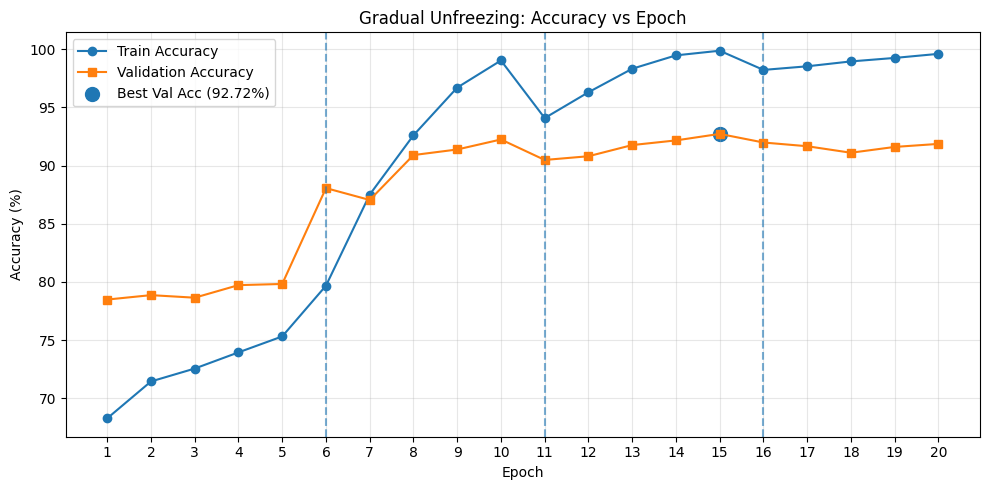

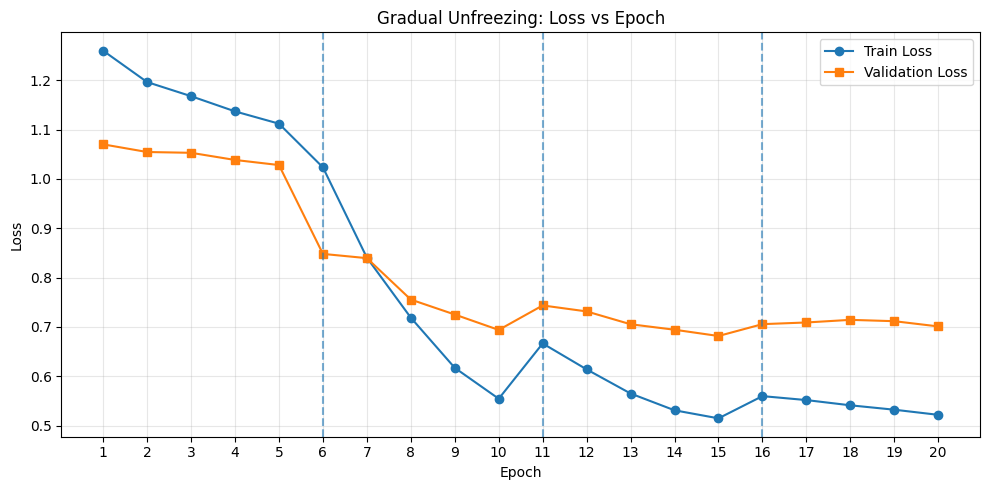

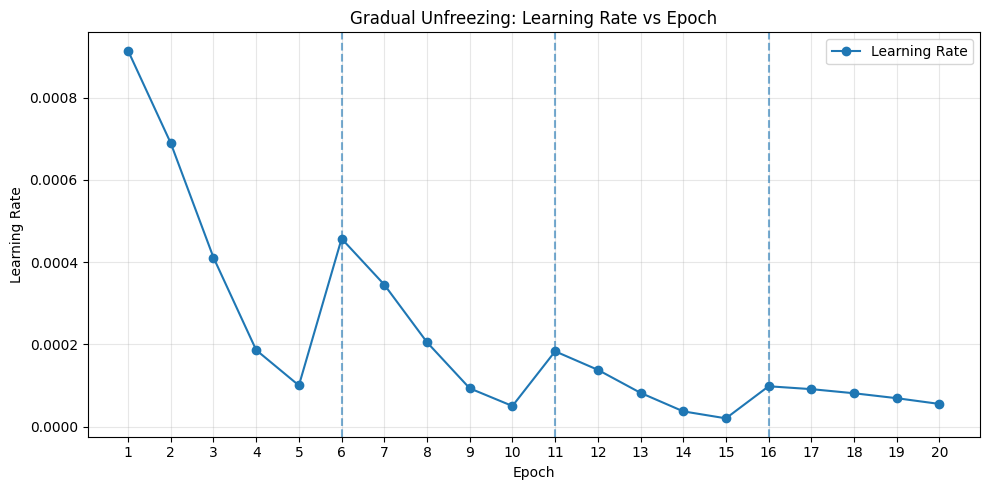

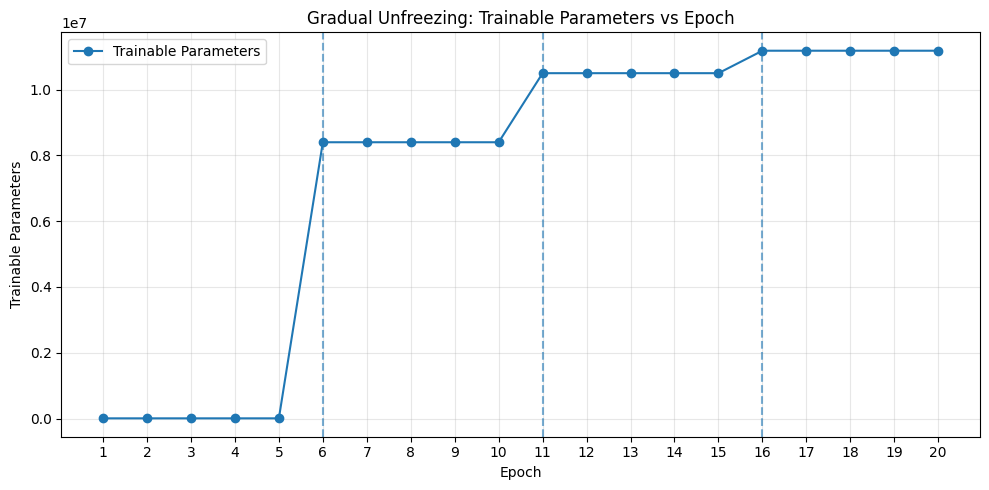

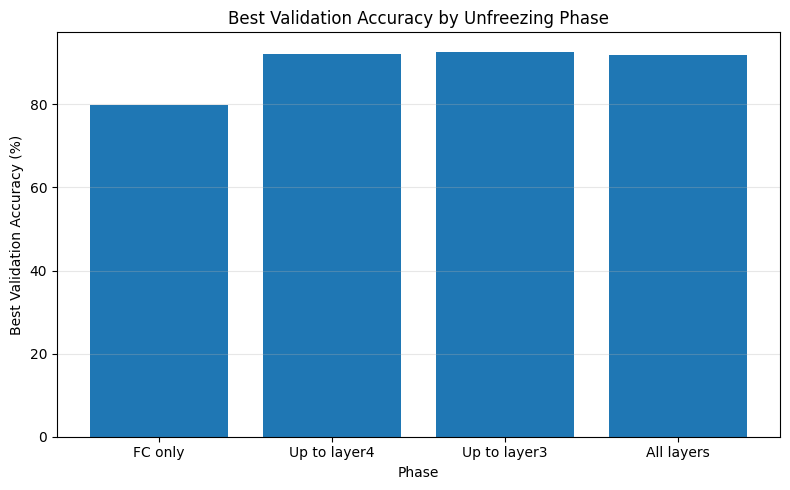

In [3]:
epochs = list(range(1, 21))

train_loss = [
    1.2596, 1.1961, 1.1675, 1.1367, 1.1118,
    1.0233, 0.8404, 0.7188, 0.6172, 0.5546,
    0.6666, 0.6141, 0.5652, 0.5312, 0.5149,
    0.5599, 0.5519, 0.5413, 0.5324, 0.5220
]

train_acc = [
    68.27, 71.44, 72.55, 73.94, 75.31,
    79.67, 87.50, 92.60, 96.70, 99.03,
    94.08, 96.30, 98.32, 99.47, 99.87,
    98.22, 98.53, 98.95, 99.25, 99.60
]

val_loss = [
    1.0699, 1.0544, 1.0528, 1.0383, 1.0280,
    0.8480, 0.8394, 0.7555, 0.7252, 0.6940,
    0.7436, 0.7315, 0.7055, 0.6944, 0.6817,
    0.7057, 0.7091, 0.7144, 0.7117, 0.7011
]

val_acc = [
    78.48, 78.86, 78.64, 79.72, 79.82,
    88.06, 87.04, 90.90, 91.38, 92.24,
    90.48, 90.80, 91.76, 92.16, 92.72,
    91.98, 91.66, 91.10, 91.60, 91.86
]

lr_values = [
    0.000914, 0.000689, 0.000411, 0.000186, 0.000100,
    0.000457, 0.000345, 0.000205, 0.000093, 0.000050,
    0.000183, 0.000138, 0.000082, 0.000037, 0.000020,
    0.000098, 0.000091, 0.000081, 0.000069, 0.000055
]

# Trainable parameters by epoch (constant within each phase)
trainable_params = (
    [5130] * 5 +
    [8398858] * 5 +
    [10498570] * 5 +
    [11181642] * 5
)

# Phase boundaries and labels
phase_starts = [1, 6, 11, 16]
phase_labels = ["FC only", "Up to layer4", "Up to layer3", "All layers"]

best_epoch = 15
best_val_acc = 92.72

# -----------------------------
# Helper to mark phase changes
# -----------------------------
def add_phase_lines():
    for x in [6, 11, 16]:
        plt.axvline(x=x, linestyle="--", alpha=0.6)

# -----------------------------
# 1. Accuracy plot
# -----------------------------
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_acc, marker="o", label="Train Accuracy")
plt.plot(epochs, val_acc, marker="s", label="Validation Accuracy")
add_phase_lines()
plt.scatter(best_epoch, best_val_acc, s=100, label=f"Best Val Acc ({best_val_acc:.2f}%)")
plt.title("Gradual Unfreezing: Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 2. Loss plot
# -----------------------------
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_loss, marker="o", label="Train Loss")
plt.plot(epochs, val_loss, marker="s", label="Validation Loss")
add_phase_lines()
plt.title("Gradual Unfreezing: Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 3. Learning rate plot
# -----------------------------
plt.figure(figsize=(10, 5))
plt.plot(epochs, lr_values, marker="o", label="Learning Rate")
add_phase_lines()
plt.title("Gradual Unfreezing: Learning Rate vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 4. Trainable parameters plot
# -----------------------------
plt.figure(figsize=(10, 5))
plt.plot(epochs, trainable_params, marker="o", label="Trainable Parameters")
add_phase_lines()
plt.title("Gradual Unfreezing: Trainable Parameters vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Trainable Parameters")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 5. Optional summary bar chart
# -----------------------------
phase_best_val_acc = [79.82, 92.24, 92.72, 91.98]
phase_param_counts = [5130, 8398858, 10498570, 11181642]

plt.figure(figsize=(8, 5))
plt.bar(phase_labels, phase_best_val_acc)
plt.title("Best Validation Accuracy by Unfreezing Phase")
plt.xlabel("Phase")
plt.ylabel("Best Validation Accuracy (%)")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6: Architecture Summary

In [ ]:
!pip install torchinfo

In [ ]:
from torchinfo import summary
import torch

In [ ]:
base = CNN().to(device)
improved = custom_CNN().to(device)
resnet_frozen = pretrained_ResNet(strategy="frozen").to(device)
resnet_full = pretrained_ResNet(strategy="full").to(device)

In [ ]:
# Baseline CNN
summary(
    base,
    input_size=(1, 3, 32, 32),
    col_names=["input_size", "output_size", "num_params"]
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CNN                                      [1, 3, 32, 32]            [1, 10]                   --
├─Conv2d: 1-1                            [1, 3, 32, 32]            [1, 6, 28, 28]            456
├─MaxPool2d: 1-2                         [1, 6, 28, 28]            [1, 6, 14, 14]            --
├─Conv2d: 1-3                            [1, 6, 14, 14]            [1, 16, 10, 10]           2,416
├─MaxPool2d: 1-4                         [1, 16, 10, 10]           [1, 16, 5, 5]             --
├─Linear: 1-5                            [1, 400]                  [1, 120]                  48,120
├─Linear: 1-6                            [1, 120]                  [1, 84]                   10,164
├─Linear: 1-7                            [1, 84]                   [1, 10]                   850
Total params: 62,006
Trainable params: 62,006
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.66
Input si

In [ ]:
# Improved CNN
summary(
    improved,
    input_size=(1, 3, 32, 32),
    col_names=["input_size", "output_size", "num_params"]
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
custom_CNN                               [1, 3, 32, 32]            [1, 10]                   --
├─Conv2d: 1-1                            [1, 3, 32, 32]            [1, 32, 32, 32]           896
├─BatchNorm2d: 1-2                       [1, 32, 32, 32]           [1, 32, 32, 32]           64
├─MaxPool2d: 1-3                         [1, 32, 32, 32]           [1, 32, 16, 16]           --
├─Conv2d: 1-4                            [1, 32, 16, 16]           [1, 64, 16, 16]           18,496
├─BatchNorm2d: 1-5                       [1, 64, 16, 16]           [1, 64, 16, 16]           128
├─MaxPool2d: 1-6                         [1, 64, 16, 16]           [1, 64, 8, 8]             --
├─Conv2d: 1-7                            [1, 64, 8, 8]             [1, 128, 8, 8]            73,856
├─BatchNorm2d: 1-8                       [1, 128, 8, 8]            [1, 128, 8, 8]            256
├─MaxPool2d: 1-9        

In [ ]:
# ResNet Frozen
summary(
    resnet_frozen,
    input_size=(1, 3, 224, 224),
    col_names=["input_size", "output_size", "num_params"]
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ResNet                                   [1, 3, 224, 224]          [1, 10]                   --
├─Conv2d: 1-1                            [1, 3, 224, 224]          [1, 64, 112, 112]         (9,408)
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         [1, 64, 112, 112]         (128)
├─ReLU: 1-3                              [1, 64, 112, 112]         [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 112, 112]         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           [1, 64, 56, 56]           (36,864)
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           [1, 64, 56, 56]           (128)
│    │    └─ReLU: 

In [ ]:
# ResNet Fine-tuned
summary(
    resnet_full,
    input_size=(1, 3, 224, 224),
    col_names=["input_size", "output_size", "num_params"]
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ResNet                                   [1, 3, 224, 224]          [1, 10]                   --
├─Conv2d: 1-1                            [1, 3, 224, 224]          [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 112, 112]         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3     